# TradePulse: Final Model Training & Verification (Phase 0, 1, 2)
**Author:** TradePulse Engineering Team (IIT Patna, IMPACT Lab)  
**Target:** META (NASDAQ), 5-Minute Closed Bars, 15-Minute Forward Direction  
**Frozen Configuration:** `label_fixed_15bp`, 50% Random Forest + 50% Logistic Regression, Platt Sigmoid Calibrator  

This notebook documents and reproduces:  
1. **Phase 0:** Configuration freeze from selection artifacts.  
2. **Phase 1:** Recency weighting evaluation across predefined grid (uniform, 180d, 90d, 45d) via PurgedWalkForwardCV with paired day-block bootstrap.  
3. **Phase 2:** One-time held-out test evaluation on sealed Test Set (Sep 2 - Nov 6, 2026, 47 sessions).

In [1]:
import sys
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path(".." if Path.cwd().name == "notebooks" else ".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.train_final import run_phase1_cv, run_phase2_test_evaluation
print("Project Root:", PROJECT_ROOT)

Project Root: E:\Projects\Trading Project\TradePulse


## Phase 0: Verify Frozen Configuration

In [2]:
config_path = PROJECT_ROOT / "artifacts" / "metadata" / "final_config_final.json"
with open(config_path) as f:
    config = json.load(f)
print(json.dumps(config, indent=2))

{
  "config_version": "1.0.0-final",
  "frozen_at_utc": "2026-11-11T15:15:00Z",
  "status": "FROZEN",
  "target": {
    "label_name": "label_fixed_15bp",
    "threshold_bps": 15.0,
    "horizon_bars": 3,
    "horizon_minutes": 15,
    "classes": {
      "Down": -1,
      "Neutral": 0,
      "Up": 1
    },
    "policy": "Intraday only, last 3 bars of session dropped"
  },
  "model": {
    "model_type": "Ensemble_50_RF_50_LR",
    "weights": {
      "random_forest": 0.5,
      "logistic_regression": 0.5
    },
    "random_forest_hyperparameters": {
      "n_estimators": 150,
      "max_depth": 3,
      "min_samples_leaf": 50,
      "max_features": "sqrt",
      "class_weight": "balanced",
      "random_state": 42
    },
    "logistic_regression_hyperparameters": {
      "C": 1.0,
      "class_weight": "balanced",
      "max_iter": 1000,
      "solver": "lbfgs",
      "random_state": 42,
      "internal_scaler": "RobustScaler"
    }
  },
  "features": {
    "count": 29,
    "names": [
   

## Phase 1: Recency Weighting Grid & Paired Bootstrap Results
Grid: Uniform (no decay), 180, 90, 45 trading days.

In [3]:
p1_path = PROJECT_ROOT / "artifacts" / "metadata" / "phase1_recency_weighting_results.json"
with open(p1_path) as f:
    p1_results = json.load(f)

print("CHOSEN HALF-LIFE:", p1_results["chosen_half_life"])
print("RATIONALE:", p1_results["decision_rationale"])
print("\nGRID METRICS SUMMARY:")
grid_df = pd.DataFrame(p1_results["grid_results"]).T
display(grid_df[["ess", "ess_pct", "auc_updown", "sign_accuracy", "gross_return_bps", "net_return_8bp_bps"]])

CHOSEN HALF-LIFE: uniform
RATIONALE: Recency weighting was NOT shown to help. All paired day-block bootstrap confidence intervals for delta gross return and delta UpDown AUC clearly cross zero. Uniform weighting is retained per pre-registered protocol, preserving 100% of the effective sample size (ESS = 15,343).

GRID METRICS SUMMARY:


,ess,ess_pct,auc_updown,sign_accuracy,gross_return_bps,net_return_8bp_bps
None,15343.0,100.0,0.499043,0.494337,0.081332,-7.918668
180,14592.570632,95.108979,0.499409,0.495805,0.239865,-7.760135
90,12791.928462,83.373059,0.499217,0.497273,0.064406,-7.935594
45,8933.427812,58.224779,0.504116,0.501678,0.590523,-7.409477


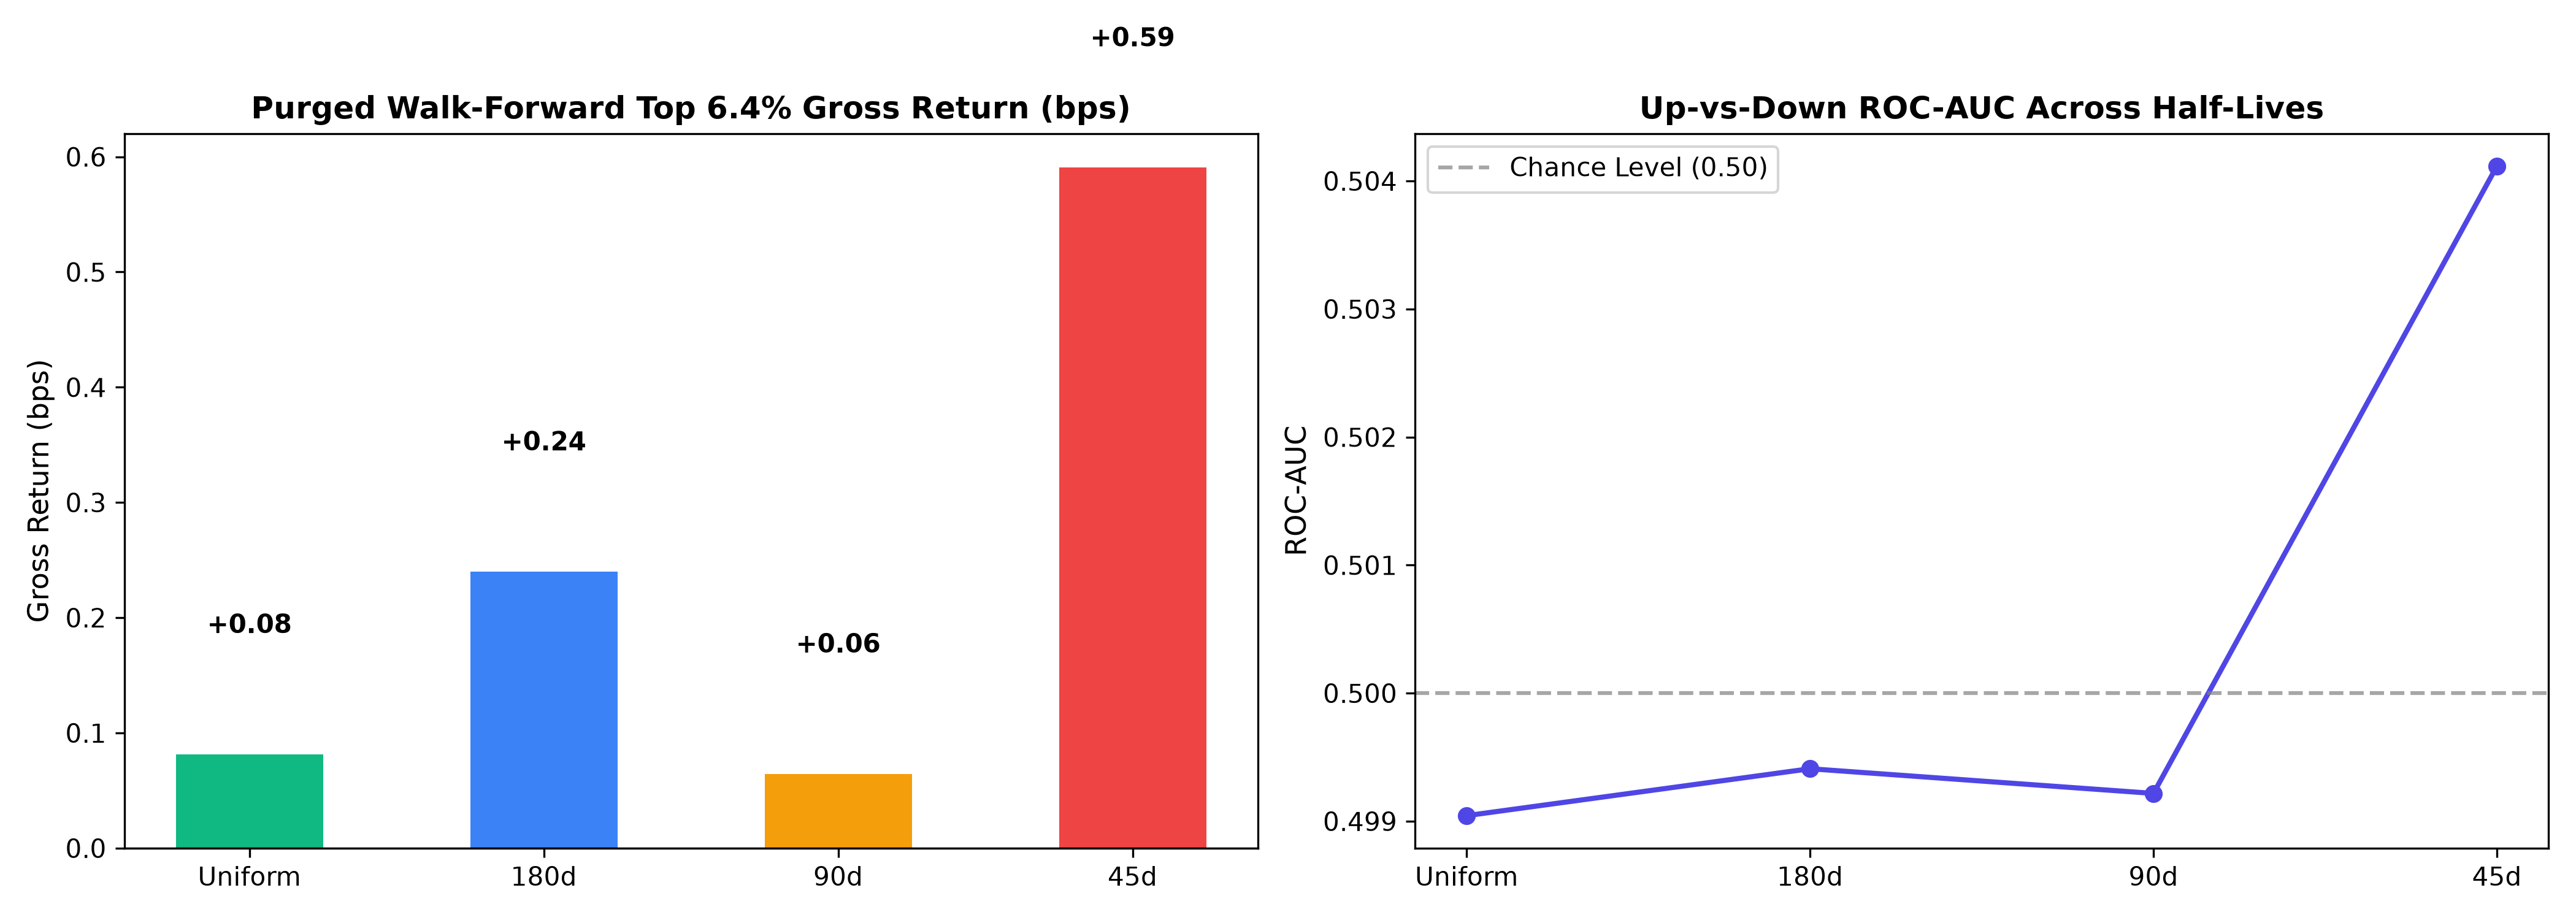

In [4]:
# Display Recency Weighting CV Figure
from IPython.display import Image, display
fig_p1 = PROJECT_ROOT / "reports" / "figures" / "recency_weighting_cv_final.png"
display(Image(filename=str(fig_p1)))

## Phase 2: One-Time Final Test Evaluation Results (Held-Out Sep 2 - Nov 6, 2026)

In [5]:
p2_path = PROJECT_ROOT / "artifacts" / "metadata" / "phase2_test_results.json"
with open(p2_path) as f:
    p2_results = json.load(f)

print("Held-Out Test Results Summary:")
for k in ["trading_days", "valid_bars", "tau_conviction_threshold", "total_signals", "signals_per_day", "zero_signal_days_pct", "precision", "binary_sign_accuracy", "auc_updown", "gross_return_bps", "net_return_8bp_bps"]:
    print(f"  {k:30s}: {p2_results[k]}")

print("\nBaselines Comparison:")
display(pd.DataFrame(p2_results["baselines_comparison"]).T)

Held-Out Test Results Summary:
  trading_days                  : 47
  valid_bars                    : 3525
  tau_conviction_threshold      : 0.2645731769161941
  total_signals                 : 1774
  signals_per_day               : 37.74
  zero_signal_days_pct          : 0.0
  precision                     : 34.16
  binary_sign_accuracy          : 54.11
  auc_updown                    : 0.5386
  gross_return_bps              : 1.29
  net_return_8bp_bps            : -6.71

Baselines Comparison:


,coverage_pct,gross_bps,net_8bp_bps
Gated_Production_Ensemble,50.3,1.29,-6.71
Unconstrained_Ensemble,100.0,1.64,-6.36
Always_Up,100.0,-0.07,-8.07
Momentum_12b,100.0,-0.18,-8.18
RSI_Rule_30_70,12.9,-1.86,-9.86
Time_of_Day_Only,100.0,1.63,-6.37


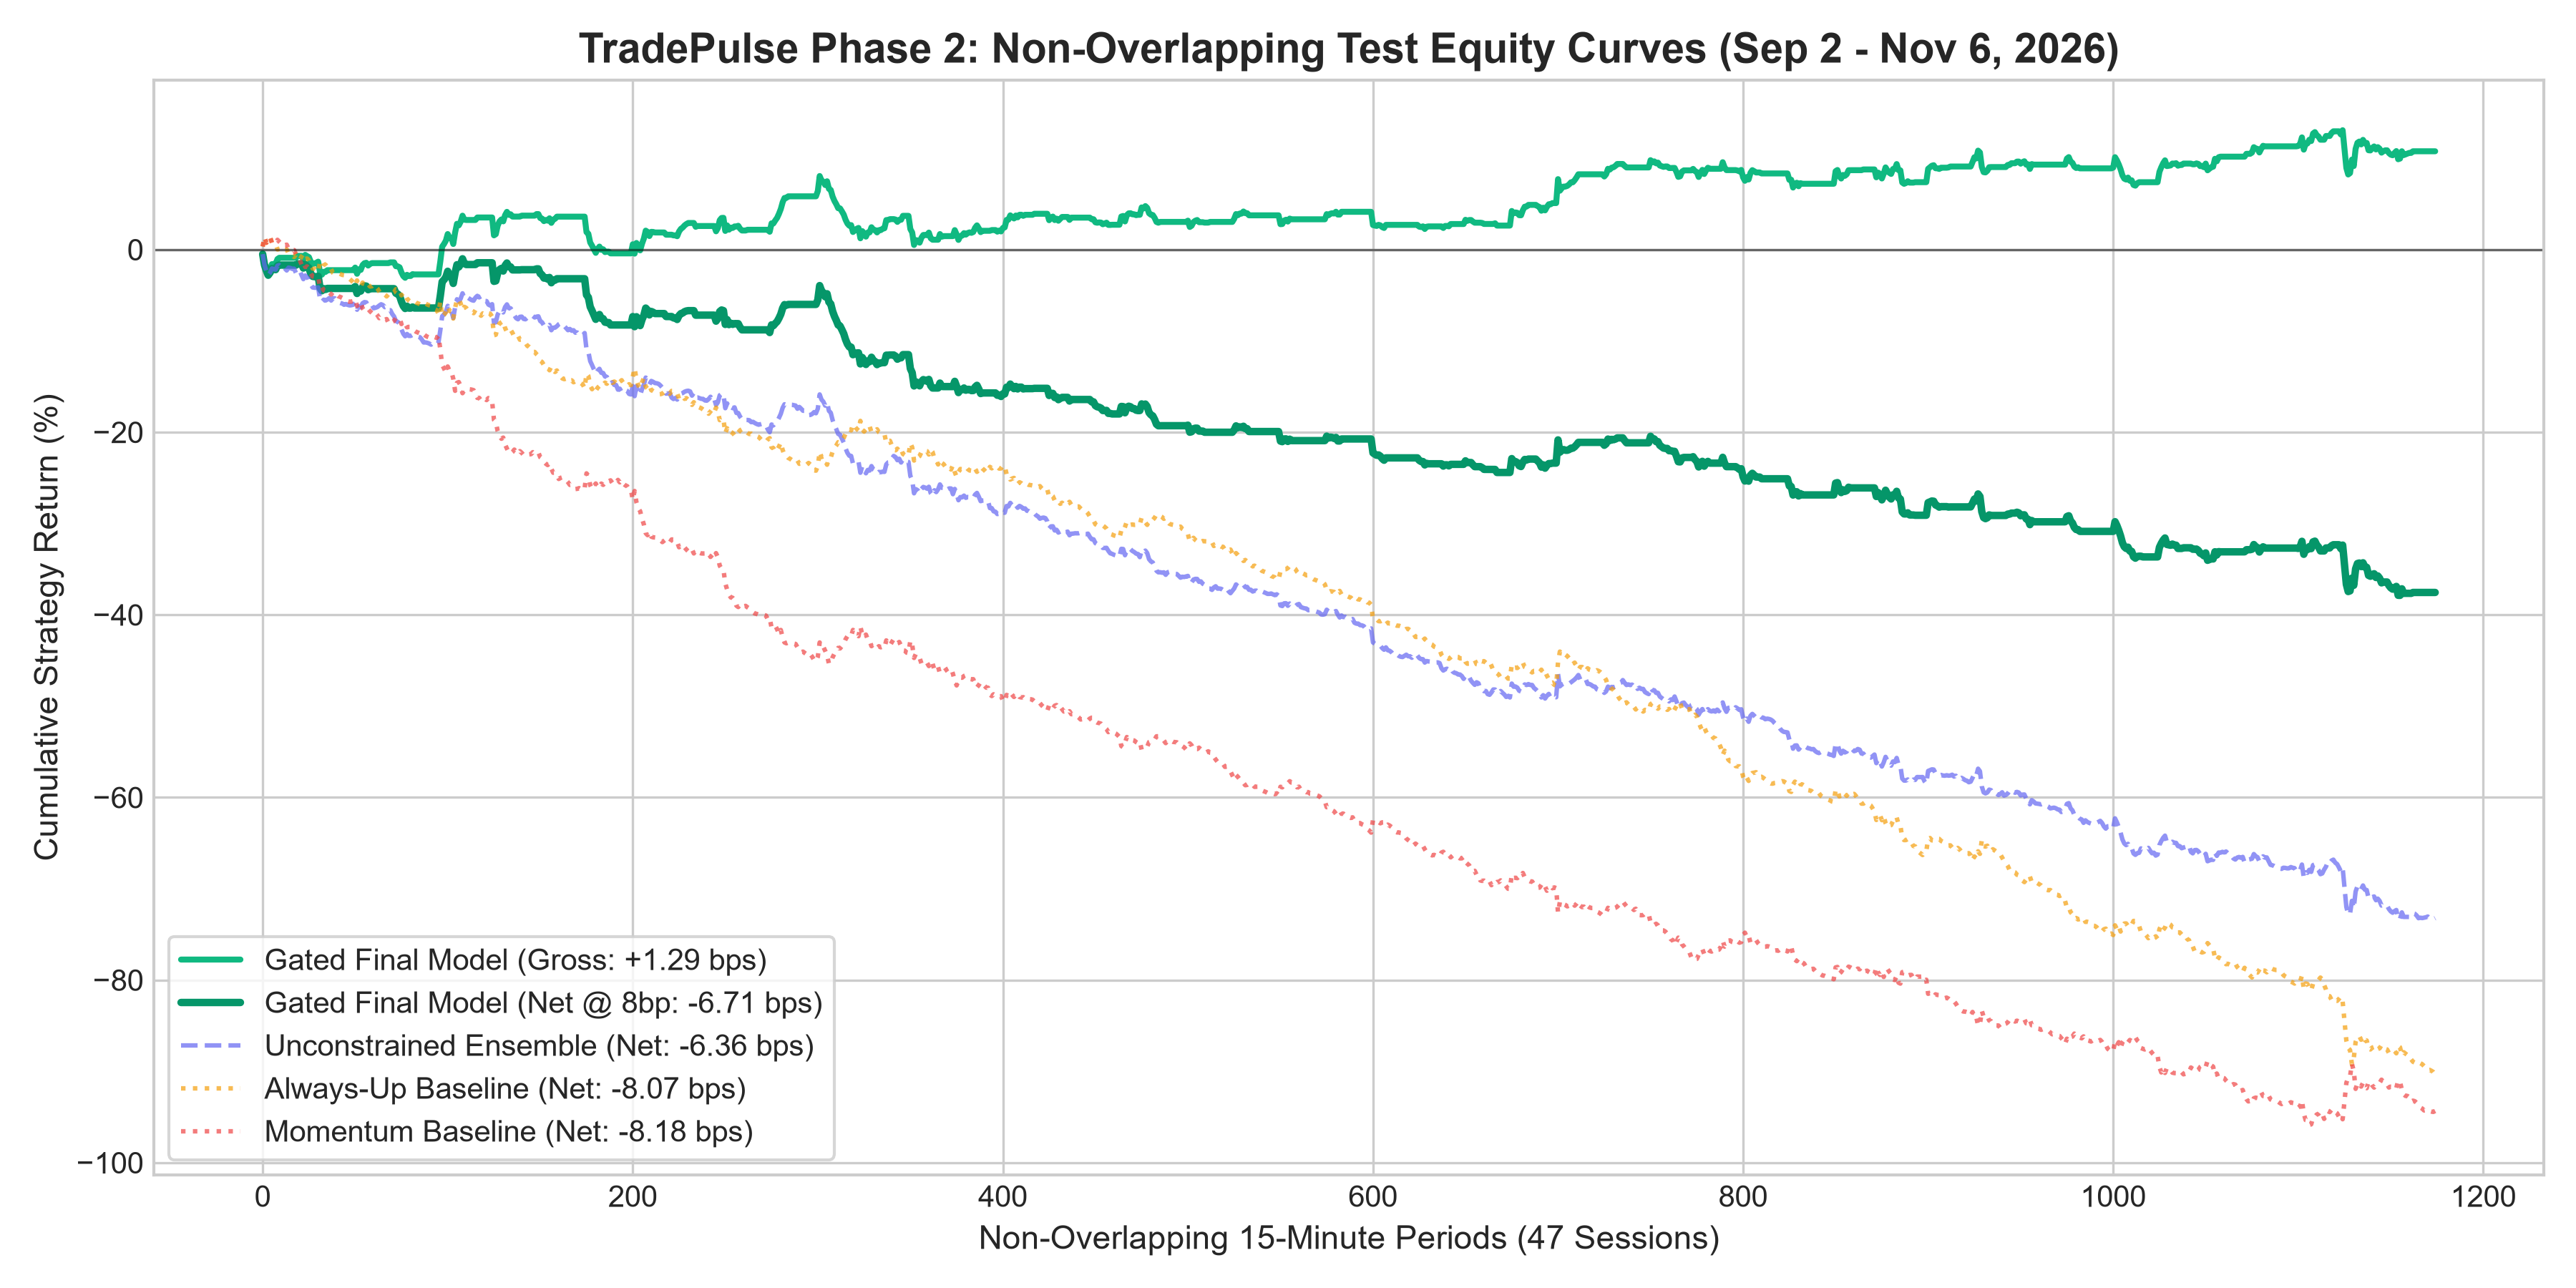

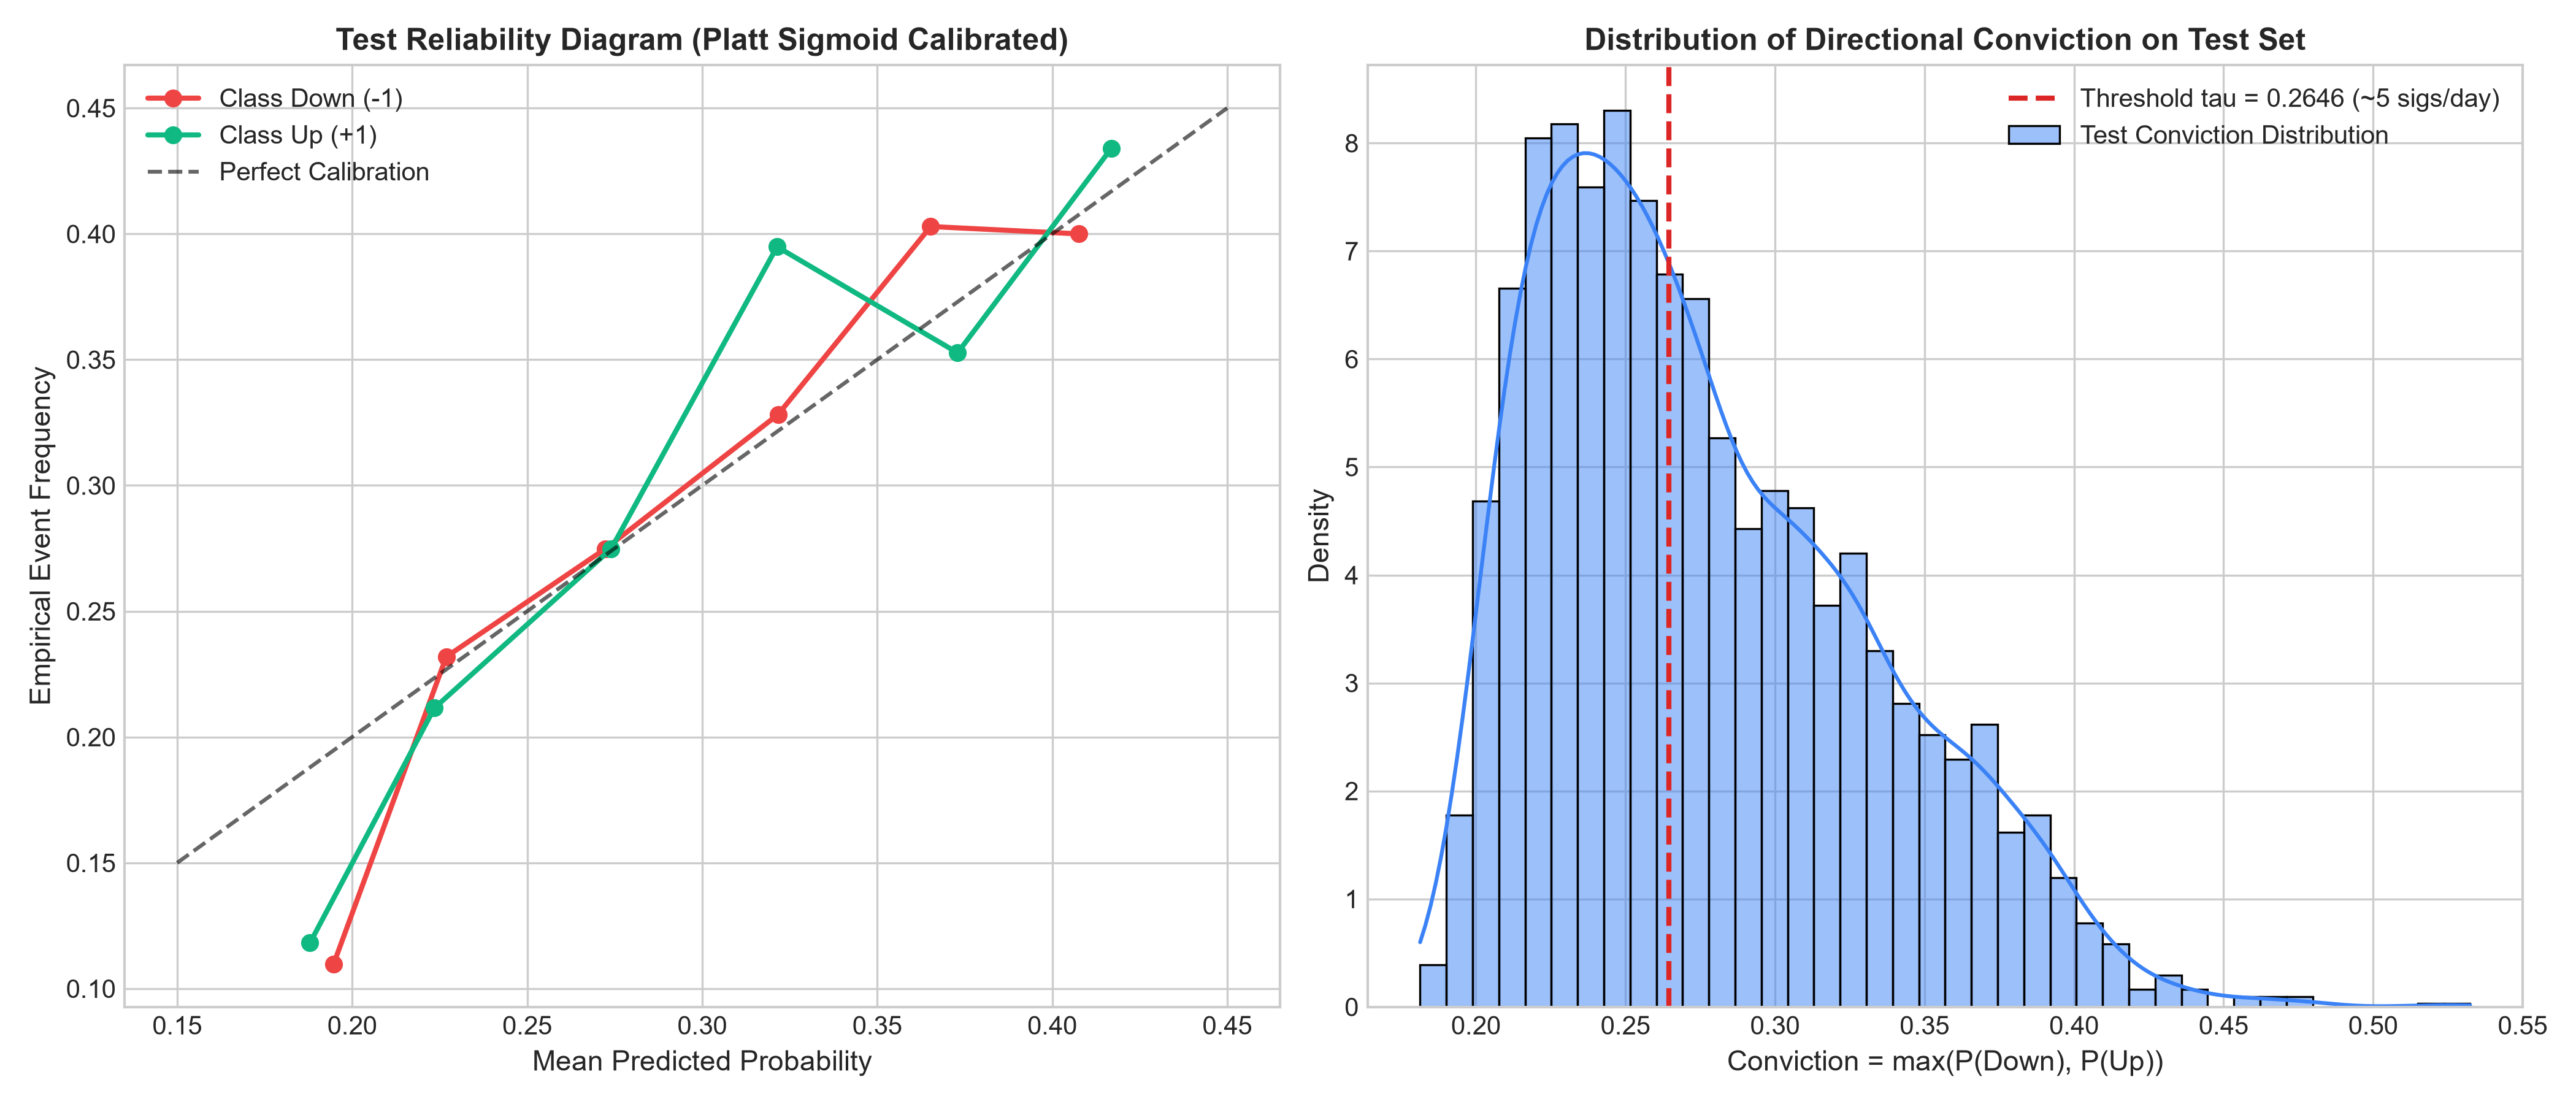

In [6]:
# Display Test Figures
fig_eq = PROJECT_ROOT / "reports" / "figures" / "test_equity_curve_final.png"
fig_cal = PROJECT_ROOT / "reports" / "figures" / "test_calibration_curve_final.png"
display(Image(filename=str(fig_eq)))
display(Image(filename=str(fig_cal)))